# Fase 3 - Modelado predictivo del acceso a internet en hogares paraguayos

**Trabajo práctico de Ciencia de Datos**  
Fuente indicada en el proyecto: Encuesta Permanente de Hogares Continua (EPHC), Anual 2025 - INE Paraguay.  
**Unidad de análisis:** hogar. **Variable objetivo:** `TIENE_INTERNET` (1 = sí; 0 = no).

Esta es la versión **ejecutada de principio a fin** del flujo de preparación, comparación, selección y evaluación de modelos. Las salidas guardadas documentan la ejecución reproducida con el CSV incluido en `data/`. La versión limpia y editable, sin salidas, se entrega en `Fase3_AccesoInternet.ipynb`.

## 1. Objetivo y alcance

El objetivo es clasificar hogares según la disponibilidad de internet a partir de características geográficas, demográficas y socioeconómicas. El análisis es predictivo y observacional: no identifica efectos causales ni determina que una variable provoque el acceso.

La evaluación se realiza dentro de la misma base de 2025. El diseño muestral complejo de la EPHC y el factor `FACTOR` no se incorporan como ponderación en este modelo; por tanto, las métricas no deben interpretarse como estimaciones ponderadas de desempeño para toda la población paraguaya.

## 2. Preparación del entorno y ubicación de archivos

La carpeta esperada es `fase3/`, con `data/`, `src/`, `notebooks/` y `output/`. El bloque siguiente identifica la raíz tanto cuando Jupyter se abre desde `notebooks/` como cuando se abre desde la carpeta del proyecto.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay)
from sklearn.inspection import permutation_importance
import joblib

HERE = Path.cwd().resolve()
CANDIDATES = [HERE / "fase3", HERE, *HERE.parents]
ROOT = next((p for p in CANDIDATES if (p / "data" / "dataset_limpio_internet_hogares.csv").is_file() and (p / "src" / "modelado_fase3.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("No se localizó la carpeta fase3/data con el CSV limpio.")
SRC_DIR = ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
from modelado_fase3 import (load_data, build_preprocessor, make_candidates,
                            score_row, FEATURES, TARGET, RANDOM_STATE)
DATA_PATH = ROOT / "data" / "dataset_limpio_internet_hogares.csv"
OUTPUT = ROOT / "output"
OUTPUT.mkdir(exist_ok=True)
print("Carpeta del proyecto:", ROOT)
print("CSV:", DATA_PATH)

Carpeta del proyecto: /mnt/data/fase3_revisado/fase3
CSV: /mnt/data/fase3_revisado/fase3/data/dataset_limpio_internet_hogares.csv


## 3. Lectura y comprobaciones iniciales

Se verifica que existan la variable objetivo y las ocho variables predictoras seleccionadas. Las filas sin etiqueta objetivo o con etiquetas distintas de 0 y 1 se excluyen del modelado. Los valores faltantes de las variables explicativas no se eliminan por lista completa: se imputan dentro de los pipelines, estimando los valores de imputación solo con los datos de entrenamiento en cada partición.

In [2]:
X, y = load_data(DATA_PATH)
print("Filas modelables:", len(X))
print("Variables predictoras:", X.columns.tolist())
print("Distribución de la variable objetivo:")
print(y.value_counts().sort_index())
print("\nValores faltantes por variable:")
print(X.isna().sum())

Filas modelables: 17092
Variables predictoras: ['AREA_DESC', 'DPTO_NOMBRE', 'TOTAL', 'EDAD_JEFE', 'SEXO_JEFE_DESC', 'ANIOS_ESTUDIO_JEFE', 'CAT_OCUP_JEFE_DESC', 'IPCM']
Distribución de la variable objetivo:
TIENE_INTERNET
0     6474
1    10618
Name: count, dtype: int64

Valores faltantes por variable:
AREA_DESC             0
DPTO_NOMBRE           0
TOTAL                 0
EDAD_JEFE             0
SEXO_JEFE_DESC        0
ANIOS_ESTUDIO_JEFE    2
CAT_OCUP_JEFE_DESC    0
IPCM                  0
dtype: int64


## 4. Selección de variables y prevención de fuga de información

Se usan `AREA_DESC`, `DPTO_NOMBRE`, `TOTAL`, `EDAD_JEFE`, `SEXO_JEFE_DESC`, `ANIOS_ESTUDIO_JEFE`, `CAT_OCUP_JEFE_DESC` e `IPCM`.

Se excluyen `UPM`, `NVIVI` y `NHOGA` por ser identificadores; `V23C1` y `V23C2` por referirse al tipo de conexión y estar condicionadas a tener internet; `V23A1` por su relación directa con la construcción de la etiqueta; `NIVEL_EDUC_JEFE` por solaparse con los años de estudio; `DECIL_ING` y `QUINTIL_ING` por ser transformaciones de ingreso; y `FACTOR` porque el objetivo aquí es entrenar un clasificador no ponderado, dejando explícita esta limitación.

`IPCM` presenta asimetría marcada y cinco valores superiores a Gs. 100 millones. Se conservan en la ejecución principal, pendientes de verificación sustantiva. Se aplica `log1p` para reducir la escala y asimetría; esto no equivale a eliminar ni winsorizar extremos.

## 5. Partición estratificada

Se separan 60% para entrenamiento, 20% para validación y 20% para prueba. La estratificación mantiene aproximadamente la proporción de hogares con y sin internet en cada subconjunto. La semilla fija en 42 facilita reproducir la misma partición.

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)
print({"entrenamiento": len(X_train), "validacion": len(X_val), "prueba": len(X_test)})

{'entrenamiento': 10255, 'validacion': 3418, 'prueba': 3419}


## 6. Preprocesamiento

El preprocesamiento está encapsulado dentro de cada `Pipeline` para evitar fuga de información. Las variables categóricas se imputan con la categoría más frecuente y se convierten mediante one-hot encoding; las numéricas se imputan con la mediana y se estandarizan; el ingreso se imputa, transforma con logaritmo `log1p` y estandariza. Las categorías no vistas se toleran con `handle_unknown="ignore"`.

In [4]:
preprocessor = build_preprocessor()
print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['AREA_DESC', 'DPTO_NOMBRE', 'SEXO_JEFE_DESC',
                                  'CAT_OCUP_JEFE_DESC']),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['TOTAL', 'EDAD_JEFE', 'ANIOS_ESTUDIO_JEFE']),
                                ('income',
                             

## 7. Modelos candidatos y validación cruzada

Se compara una línea base mayoritaria con tres algoritmos: regresión logística, Random Forest e HistGradientBoosting. Para ajustar hiperparámetros se usa validación cruzada estratificada de tres pliegues sobre el conjunto de entrenamiento y F1 como métrica principal, porque la distribución de clases no es perfectamente equilibrada y se busca balancear precisión y sensibilidad.

In [5]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
dummy = Pipeline([("preprocess", build_preprocessor()),
                  ("model", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)
cv_results, validation_results, best_models = [], [
    score_row("Baseline mayoritaria", dummy, X_val, y_val, "validacion")
], {}
for name, (estimator, param_grid) in make_candidates().items():
    pipe = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    search = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=2, refit=True)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    cv_results.append({"modelo": name, "f1_cv": search.best_score_,
                       "mejores_parametros": search.best_params_})
    validation_results.append(score_row(name, search.best_estimator_, X_val, y_val, "validacion"))
cv_table = pd.DataFrame(cv_results).sort_values("f1_cv", ascending=False)
val_table = pd.DataFrame(validation_results).sort_values(["f1", "auc_roc"], ascending=False)
cv_table

,modelo,f1_cv,mejores_parametros
2,HistGradientBoosting,0.840710,"{'model__learning_rate': 0.1, 'model__max_iter..."
1,Random Forest,0.827503,"{'model__max_depth': None, 'model__min_samples..."
0,Regresión logística,0.812187,{'model__C': 10.0}


## 8. Selección del modelo

Se selecciona el modelo con mayor F1 en validación. El AUC-ROC se utiliza como criterio secundario en caso de empate. El conjunto de prueba permanece separado hasta esta etapa para obtener una evaluación final menos sesgada por la selección.

In [6]:
val_table

,modelo,particion,accuracy,precision,recall,f1,auc_roc
3,HistGradientBoosting,validacion,0.792569,0.812832,0.865285,0.838239,0.864893
2,Random Forest,validacion,0.784377,0.827195,0.825247,0.826220,0.858477
1,Regresión logística,validacion,0.775600,0.849485,0.776260,0.811223,0.852909
0,Baseline mayoritaria,validacion,0.621123,0.621123,1.000000,0.766288,0.500000


In [7]:
selected_name = val_table.loc[val_table["modelo"] != "Baseline mayoritaria"].sort_values(
    ["f1", "auc_roc"], ascending=False
).iloc[0]["modelo"]
final_model = best_models[selected_name]
print("Modelo seleccionado:", selected_name)

Modelo seleccionado: HistGradientBoosting


## 9. Evaluación final en el conjunto de prueba

Accuracy expresa la proporción total de aciertos; precision, qué fracción de los hogares predichos con internet realmente lo tienen; recall, qué fracción de los hogares con internet se identifica; F1 combina precision y recall; AUC-ROC evalúa la capacidad de ordenar casos positivos por encima de negativos a través de umbrales.

In [8]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]
test_metrics = score_row(selected_name, final_model, X_test, y_test, "prueba")
pd.DataFrame([test_metrics])

,modelo,particion,accuracy,precision,recall,f1,auc_roc
0,HistGradientBoosting,prueba,0.802281,0.823792,0.867232,0.844954,0.869471


### Comparación final por partición y contra la línea base

El conjunto de prueba se mantiene fuera de la selección y del ajuste. En esta última sección se informa el mismo modelo en entrenamiento, validación y prueba, y se compara en prueba con la línea base de clase mayoritaria.

In [9]:
partition_metrics = pd.DataFrame([
    score_row(selected_name, final_model, X_train, y_train, "entrenamiento"),
    score_row(selected_name, final_model, X_val, y_val, "validacion"),
    test_metrics,
])
baseline_test_metrics = score_row("Baseline mayoritaria", dummy, X_test, y_test, "prueba")
partition_metrics


,modelo,particion,accuracy,precision,recall,f1,auc_roc
0,HistGradientBoosting,entrenamiento,0.810629,0.831661,0.871606,0.851165,0.886747
1,HistGradientBoosting,validacion,0.792569,0.812832,0.865285,0.838239,0.864893
2,HistGradientBoosting,prueba,0.802281,0.823792,0.867232,0.844954,0.869471


In [10]:
pd.DataFrame([test_metrics, baseline_test_metrics])


,modelo,particion,accuracy,precision,recall,f1,auc_roc
0,HistGradientBoosting,prueba,0.802281,0.823792,0.867232,0.844954,0.869471
1,Baseline mayoritaria,prueba,0.621234,0.621234,1.000000,0.766372,0.500000


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Matriz de confusión (filas=real; columnas=predicho):")
print(cm)
print(classification_report(y_test, y_pred, zero_division=0))

Matriz de confusión (filas=real; columnas=predicho):
[[ 901  394]
 [ 282 1842]]
              precision    recall  f1-score   support

           0       0.76      0.70      0.73      1295
           1       0.82      0.87      0.84      2124

    accuracy                           0.80      3419
   macro avg       0.79      0.78      0.79      3419
weighted avg       0.80      0.80      0.80      3419



### Examen de errores y posible disparidad por área

Se separan falsos positivos (hogares sin internet clasificados como conectados) y falsos negativos (hogares conectados clasificados como no conectados). La tasa se calcula dentro de cada clase real y área. Es un diagnóstico de la partición de prueba, no una estimación poblacional ponderada.

In [12]:
test_detail = X_test.copy()
test_detail["TIENE_INTERNET_REAL"] = y_test.values
test_detail["TIENE_INTERNET_PREDICHO"] = y_pred
test_detail["PROBABILIDAD_INTERNET"] = y_prob
test_detail["ERROR"] = test_detail["TIENE_INTERNET_REAL"] != test_detail["TIENE_INTERNET_PREDICHO"]
error_area = (test_detail.groupby(["TIENE_INTERNET_REAL", "AREA_DESC"])
              .agg(casos=("ERROR", "size"), errores=("ERROR", "sum"))
              .reset_index())
error_area["tasa_error"] = error_area["errores"] / error_area["casos"]
error_area


,TIENE_INTERNET_REAL,AREA_DESC,casos,errores,tasa_error
0,0,Rural,903,160,0.177187
1,0,Urbana,392,234,0.596939
2,1,Rural,526,206,0.391635
3,1,Urbana,1598,76,0.047559


In [13]:
fp_mask = (test_detail["TIENE_INTERNET_REAL"] == 0) & (test_detail["TIENE_INTERNET_PREDICHO"] == 1)
fn_mask = (test_detail["TIENE_INTERNET_REAL"] == 1) & (test_detail["TIENE_INTERNET_PREDICHO"] == 0)
error_summary = pd.DataFrame({
    "tipo": ["Falsos positivos", "Falsos negativos"],
    "casos": [int(fp_mask.sum()), int(fn_mask.sum())],
    "errores_confianza_alta": [int((fp_mask & (test_detail["PROBABILIDAD_INTERNET"] >= .90)).sum()),
                                  int((fn_mask & (test_detail["PROBABILIDAD_INTERNET"] <= .10)).sum())]
})
error_summary


,tipo,casos,errores_confianza_alta
0,Falsos positivos,394,36
1,Falsos negativos,282,14


## 10. Visualizaciones y análisis de errores

La matriz de confusión muestra los aciertos y errores por clase. La curva ROC resume el desempeño para diferentes umbrales. La importancia por permutación estima cuánto cae el F1 al desordenar una variable de validación manteniendo las demás; describe relevancia predictiva del modelo y no debe interpretarse como efecto causal.

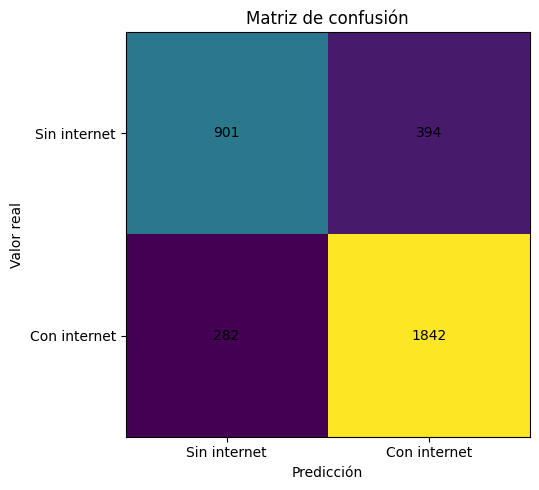

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, interpolation="nearest")
ax.set(title="Matriz de confusión", xlabel="Predicción", ylabel="Valor real")
ax.set_xticks([0, 1], ["Sin internet", "Con internet"])
ax.set_yticks([0, 1], ["Sin internet", "Con internet"])
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()

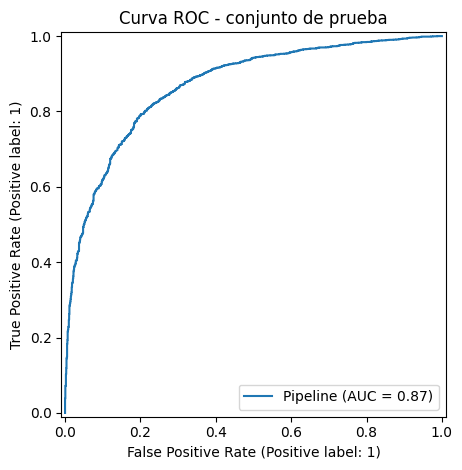

In [15]:
RocCurveDisplay.from_estimator(final_model, X_test, y_test)
plt.title("Curva ROC - conjunto de prueba")
plt.tight_layout(); plt.show()

In [16]:
perm = permutation_importance(final_model, X_val, y_val, scoring="f1",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=2)
importance = pd.DataFrame({"variable": FEATURES,
                           "importancia_media": perm.importances_mean,
                           "desvio_estandar": perm.importances_std}).sort_values(
                               "importancia_media", ascending=False)
importance

,variable,importancia_media,desvio_estandar
7,IPCM,0.055842,0.005044
0,AREA_DESC,0.023708,0.001080
2,TOTAL,0.021909,0.002575
5,ANIOS_ESTUDIO_JEFE,0.020210,0.002458
1,DPTO_NOMBRE,0.009888,0.001796
3,EDAD_JEFE,0.006196,0.001891
6,CAT_OCUP_JEFE_DESC,0.002557,0.000624
4,SEXO_JEFE_DESC,0.000894,0.000429


## 11. Guardado de resultados y modelo

Se guardan métricas, matriz de confusión, reporte, errores, importancia, gráficos y el pipeline completo serializado. Al guardar el pipeline completo también se conservan los pasos de imputación, transformación y codificación.

In [17]:
# Se guardan los resultados reproducibles relevantes de esta ejecución.
joblib.dump(final_model, OUTPUT / "modelo_acceso_internet.joblib")
cv_table.to_csv(OUTPUT / "comparacion_validacion_cruzada.csv", index=False)
val_table.to_csv(OUTPUT / "comparacion_validacion.csv", index=False)
partition_metrics.to_csv(OUTPUT / "metricas_particiones.csv", index=False)
pd.DataFrame([test_metrics, baseline_test_metrics]).to_csv(OUTPUT / "comparacion_prueba.csv", index=False)
importance.to_csv(OUTPUT / "importancia_permutacion.csv", index=False)
error_area.to_csv(OUTPUT / "diagnostico_errores_por_area.csv", index=False)
test_detail.loc[test_detail["ERROR"]].to_csv(OUTPUT / "predicciones_errores_prueba.csv", index=False)
print("Artefactos guardados en:", OUTPUT)


Artefactos guardados en: /mnt/data/fase3_revisado/fase3/output


## 12. Interpretación y límites

- El modelo ofrece una clasificación razonablemente discriminante dentro de esta partición de la EPHC 2025; no garantiza el mismo rendimiento en otro año o fuente.
- El ingreso per cápita, el área, el tamaño del hogar y los años de estudio del jefe aparecen entre las variables con mayor importancia predictiva por permutación en esta ejecución.
- Una importancia elevada no prueba causalidad ni permite concluir que modificar esa variable produciría acceso a internet.
- La evaluación es no ponderada y no ajusta explícitamente por estratos, conglomerados o factores de expansión. Las cifras no sustituyen estimaciones oficiales del INE.
- Los umbrales y errores de clasificación deben discutirse según el uso previsto. No es adecuado usar este modelo para negar servicios, beneficios o derechos a hogares.

